# Task 3: Multi-Class Image Classification using CNN

**Dataset:** CIFAR-10  
**Framework:** TensorFlow / Keras

This notebook builds and trains a custom convolutional neural network (CNN) to classify 32×32 RGB images into 10 categories. It includes data augmentation, training callbacks, accuracy/loss curves, test evaluation, a classification report, a confusion matrix, sample predictions, and model saving.

**Recommended runtime:** Google Colab with GPU enabled, although CPU execution is also supported.

## 1. Import libraries

In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report, confusion_matrix

print("TensorFlow version:", tf.__version__)
print("Available GPUs:", tf.config.list_physical_devices("GPU"))

TensorFlow version: 2.21.0
Available GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Load the CIFAR-10 dataset

In [2]:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.cifar10.load_data()

class_names = [
    "Airplane", "Automobile", "Bird", "Cat", "Deer",
    "Dog", "Frog", "Horse", "Ship", "Truck"
]

print("Training images:", x_train.shape)
print("Training labels:", y_train.shape)
print("Testing images:", x_test.shape)
print("Testing labels:", y_test.shape)

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 448s 3us/step
Training images: (50000, 32, 32, 3)
Training labels: (50000, 1)
Testing images: (10000, 32, 32, 3)
Testing labels: (10000, 1)


## 3. Normalize the images and prepare labels
Pixel values are converted from the range 0–255 to 0–1. Labels are flattened to one-dimensional arrays.

In [3]:
x_train = x_train.astype("float32") / 255.0
x_test = x_test.astype("float32") / 255.0

y_train = y_train.flatten()
y_test = y_test.flatten()

print("Training pixel range:", x_train.min(), "to", x_train.max())
print("Training labels shape:", y_train.shape)

Training pixel range: 0.0 to 1.0
Training labels shape: (50000,)


## 4. Visualize sample images

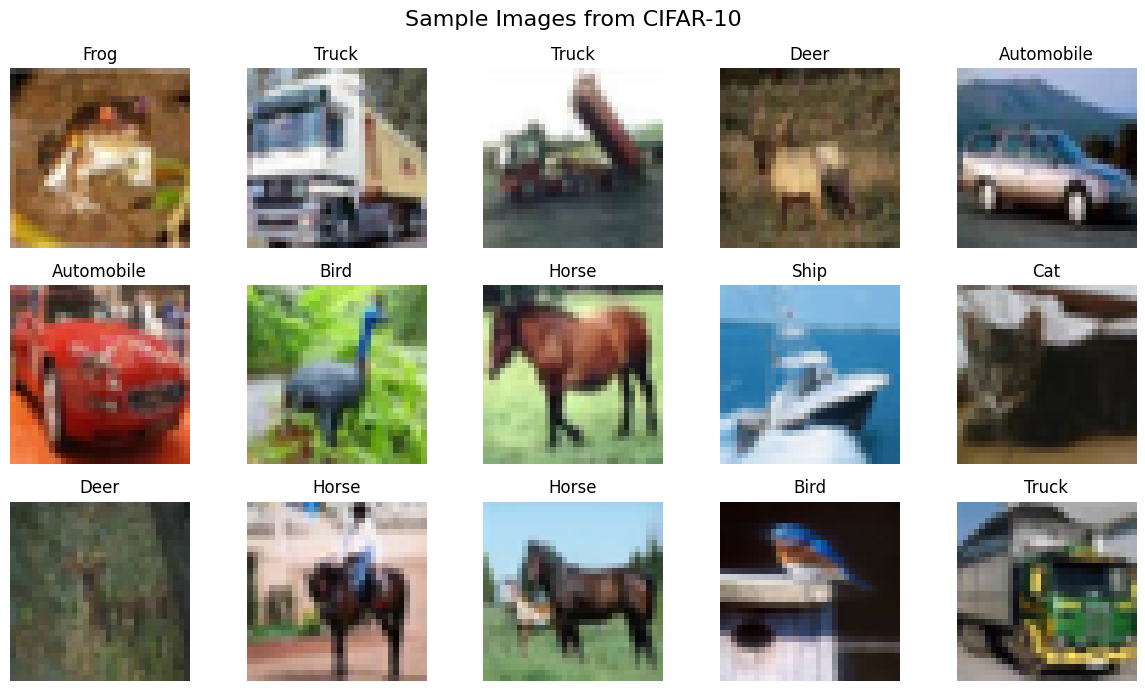

In [4]:
plt.figure(figsize=(12, 7))

for i in range(15):
    plt.subplot(3, 5, i + 1)
    plt.imshow(x_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.suptitle("Sample Images from CIFAR-10", fontsize=16)
plt.tight_layout()
plt.show()

## 5. Create a data augmentation pipeline
Random horizontal flipping, rotation, zoom, and translation help the model generalize and reduce overfitting. Augmentation is applied during training only.

In [5]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomTranslation(0.1, 0.1)
], name="data_augmentation")

## 6. Build the custom CNN architecture
The model uses multiple convolutional layers for feature extraction, max-pooling for spatial downsampling, batch normalization for more stable training, and dropout for regularization.

In [6]:
model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(32, 32, 3)),
    data_augmentation,

    tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(32, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.25),

    tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(64, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.30),

    tf.keras.layers.Conv2D(128, (3, 3), padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.MaxPooling2D((2, 2)),
    tf.keras.layers.Dropout(0.35),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Dropout(0.5),

    tf.keras.layers.Dense(10, activation="softmax")
], name="cifar10_custom_cnn")

model.summary()

Model: "cifar10_custom_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ data_augmentation (Sequential)  │ (None, 32, 32, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 32, 32, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 8, 8, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       262,272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 404,394 (1.54 MB)

 Trainable params: 403,690 (1.54 MB)

 Non-trainable params: 704 (2.75 KB)

## 7. Compile the model
Sparse categorical crossentropy is suitable because the labels are integer class IDs rather than one-hot encoded vectors.

In [7]:
model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

## 8. Configure training callbacks
Early stopping restores the weights from the epoch with the best validation loss. ReduceLROnPlateau lowers the learning rate when validation loss stops improving.

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=7,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

## 9. Train the CNN
The training set is split so that 20% is used for validation. The test set remains untouched until final evaluation.

In [17]:
EPOCHS = 40
BATCH_SIZE = 64

history = model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 11s 18ms/step - accuracy: 0.6765 - loss: 0.9312 - val_accuracy: 0.7018 - val_loss: 0.8564 - learning_rate: 2.5000e-04
Epoch 2/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 9s 15ms/step - accuracy: 0.6821 - loss: 0.9109 - val_accuracy: 0.6869 - val_loss: 0.9118 - learning_rate: 2.5000e-04
Epoch 3/40
624/625 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.6830 - loss: 0.9062
Epoch 3: ReduceLROnPlateau reducing learning rate to 0.0001250000059371814.
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6848 - loss: 0.9067 - val_accuracy: 0.6839 - val_loss: 0.9096 - learning_rate: 2.5000e-04
Epoch 4/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6942 - loss: 0.8792 - val_accuracy: 0.7188 - val_loss: 0.8037 - learning_rate: 1.2500e-04
Epoch 5/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 16ms/step - accuracy: 0.6957 - loss: 0.8788 - val_accuracy: 0.7099 - val_loss: 0.8299 - learning_rate: 1.2500e-04
Epoch 6/40
625/625 ━━━━━━━━━━━━━━━━━━━━ 10s 15ms/step - acc

## 10. Plot training and validation accuracy

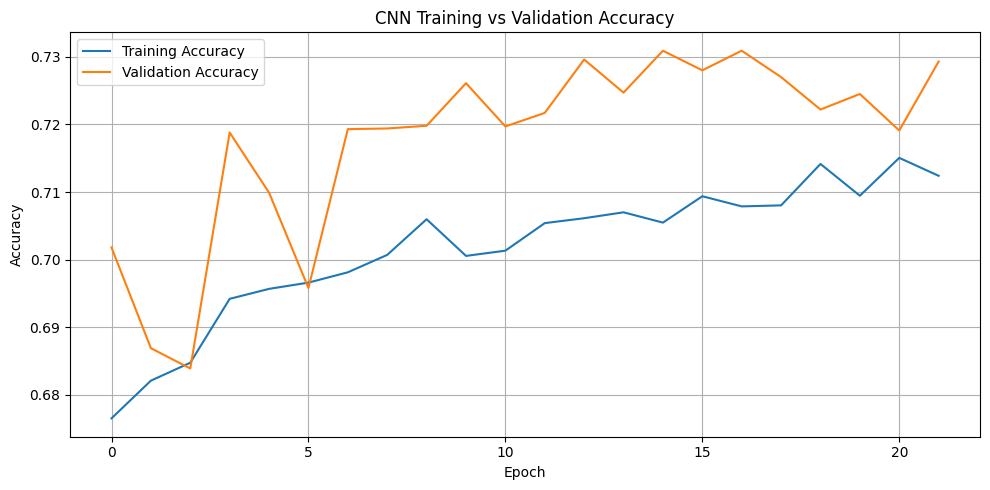

In [18]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("CNN Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("accuracy_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## 11. Plot training and validation loss

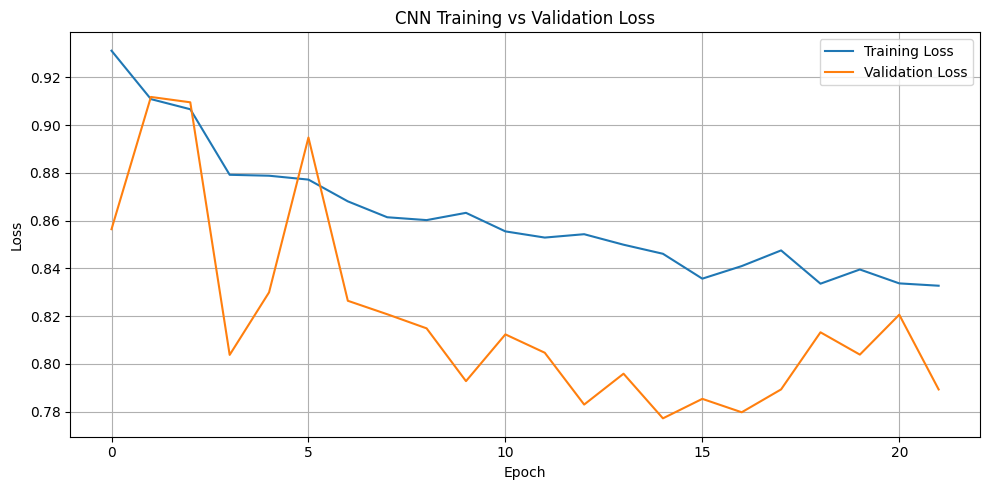

In [19]:
plt.figure(figsize=(10, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("CNN Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("loss_curve.png", dpi=300, bbox_inches="tight")
plt.show()

## 12. Evaluate on the test dataset

In [20]:
test_loss, test_accuracy = model.evaluate(x_test, y_test, verbose=1)

print(f"Test loss: {test_loss:.4f}")
print(f"Test accuracy: {test_accuracy * 100:.2f}%")

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.7200 - loss: 0.7991
Test loss: 0.7991
Test accuracy: 72.00%


## 13. Generate predictions and classification report

In [21]:
y_probabilities = model.predict(x_test, batch_size=128, verbose=1)
y_pred = np.argmax(y_probabilities, axis=1)

print(classification_report(
    y_test,
    y_pred,
    target_names=class_names,
    digits=4
))

79/79 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step
              precision    recall  f1-score   support

    Airplane     0.7686    0.7940    0.7811      1000
  Automobile     0.8664    0.8950    0.8805      1000
        Bird     0.8245    0.4370    0.5712      1000
         Cat     0.6500    0.4550    0.5353      1000
        Deer     0.7092    0.5390    0.6125      1000
         Dog     0.7790    0.5850    0.6682      1000
        Frog     0.4612    0.9560    0.6222      1000
       Horse     0.8103    0.7860    0.7980      1000
        Ship     0.8635    0.8730    0.8682      1000
       Truck     0.7726    0.8800    0.8228      1000

    accuracy                         0.7200     10000
   macro avg     0.7505    0.7200    0.7160     10000
weighted avg     0.7505    0.7200    0.7160     10000



## 14. Plot the confusion matrix

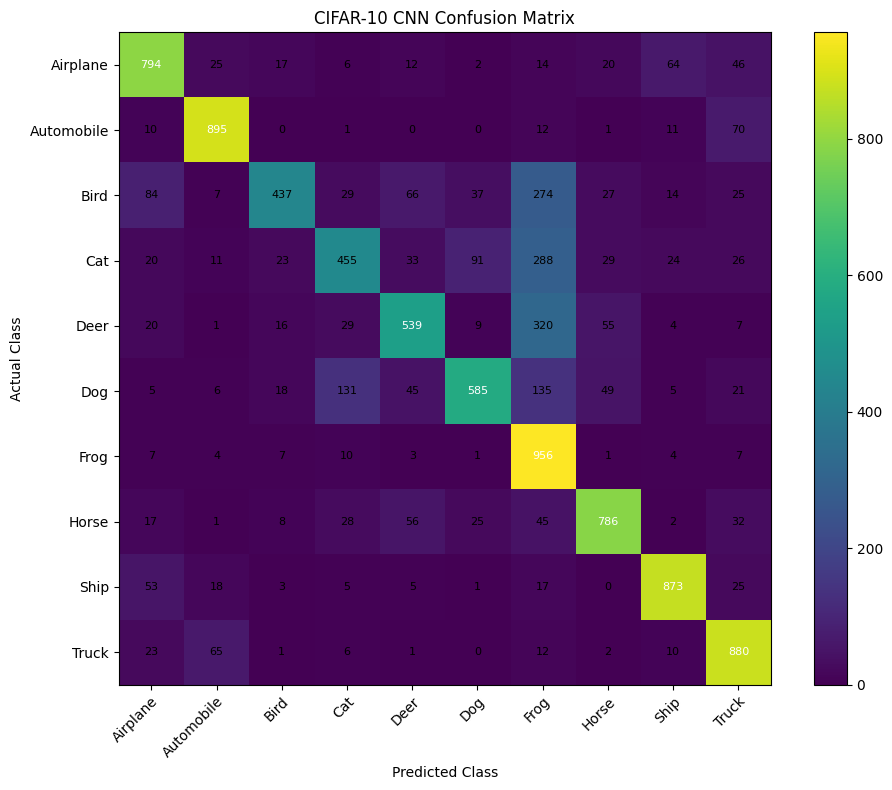

In [22]:
cm = confusion_matrix(y_test, y_pred)

fig, ax = plt.subplots(figsize=(10, 8))
image = ax.imshow(cm, interpolation="nearest")
fig.colorbar(image, ax=ax)

ax.set(
    xticks=np.arange(len(class_names)),
    yticks=np.arange(len(class_names)),
    xticklabels=class_names,
    yticklabels=class_names,
    xlabel="Predicted Class",
    ylabel="Actual Class",
    title="CIFAR-10 CNN Confusion Matrix"
)

plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")

threshold = cm.max() / 2
for row in range(cm.shape[0]):
    for col in range(cm.shape[1]):
        ax.text(
            col, row, format(cm[row, col], "d"),
            ha="center", va="center",
            color="white" if cm[row, col] > threshold else "black",
            fontsize=8
        )

fig.tight_layout()
plt.savefig("confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

## 15. Visualize sample predictions

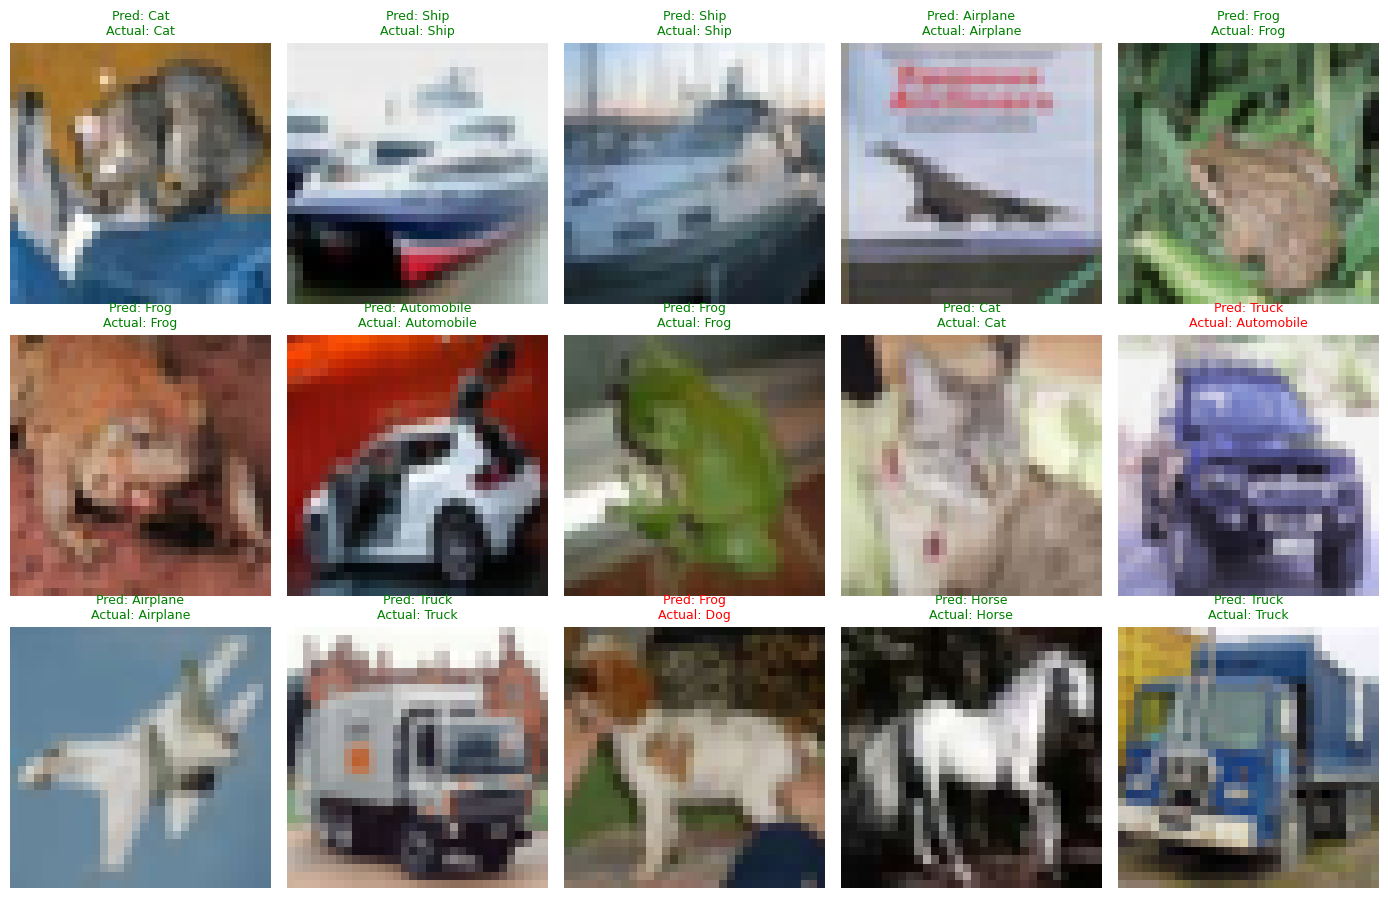

In [23]:
number_of_images = 15

plt.figure(figsize=(14, 9))

for i in range(number_of_images):
    predicted_class = int(y_pred[i])
    actual_class = int(y_test[i])
    correct = predicted_class == actual_class

    plt.subplot(3, 5, i + 1)
    plt.imshow(x_test[i])
    plt.title(
        f"Pred: {class_names[predicted_class]}\nActual: {class_names[actual_class]}",
        color="green" if correct else "red",
        fontsize=9
    )
    plt.axis("off")

plt.tight_layout()
plt.savefig("sample_predictions.png", dpi=300, bbox_inches="tight")
plt.show()

## 16. Save the trained model

In [24]:
model.save("cifar10_cnn_model.keras")
print("Model saved as cifar10_cnn_model.keras")

Model saved as cifar10_cnn_model.keras


## 17. Final observations

After running the notebook, record your actual results:

- **Test accuracy:** use the value printed in Section 12.
- **Test loss:** use the value printed in Section 12.
- **Best validation performance:** inspect the accuracy and loss curves.
- **Class-wise performance:** inspect precision, recall, and F1-score in the classification report.
- **Common misclassifications:** inspect the confusion matrix.

Do not enter estimated metrics as experimental results. The saved model and generated plots can be included with your assignment submission.